# 20 日价格涨跌幅 Top 10 滚动回测：做多与做空

本 Notebook 独立回测两个策略，各自使用 50 万元初始资金、每个品种最多一手、组合最多 10 个品种：

1. **20 日涨幅 Top 10 做多**：进入涨幅 Top 10 开多一手，跌出 Top 10 后平仓。
2. **20 日跌幅 Bottom 10 做空**：进入跌幅最大的 10 个品种开空一手，跌出 Bottom 10 后平空。

两种策略都按滚动榜单交易，信号在当前观察时点产生，下一条该品种行情记录成交。

In [188]:
from bisect import bisect_right
from collections import defaultdict
from csv import reader, DictWriter
from datetime import datetime
from heapq import merge
from itertools import groupby
from pathlib import Path
from statistics import median
import math
import re

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.font_manager import FontProperties

BASE_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "小时Buy_And_Hold").is_dir()), None)
if BASE_DIR is None:
    raise FileNotFoundError("找不到 data/小时Buy_And_Hold；请从项目根目录或 notebooks/ 运行。")
DATA_DIR = BASE_DIR / "data" / "小时Buy_And_Hold"
OUTPUT_DIR = BASE_DIR / "backtest_output" / "5day_top10_long_short"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INITIAL_CAPITAL = 500_000.0
TOP_K = 5
LOOKBACK_DAYS = 5
START_AT = "2024-01-02 09:30:00"
END_AT = None  # None 表示取数据覆盖到的最后时点
ONE_WAY_FEE_RATE = 0.0

START_DT = datetime.fromisoformat(START_AT)
print("项目目录：", BASE_DIR)
print("回测时间范围：", START_DT, "到", END_AT)
print(f"“规则：{LOOKBACK_DAYS}日涨幅 Top {TOP_K} 做多，跌出平仓；{LOOKBACK_DAYS}日跌幅 Bottom {TOP_K} 做空，跌出平仓")
print("资金：", f"¥{INITIAL_CAPITAL:,.0f}", "；每品种最多一手；每个组合最多", TOP_K, "个品种")

项目目录： d:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking
回测时间范围： 2024-01-02 09:30:00 到 None
“规则：5日涨幅 Top 5 做多，跌出平仓；5日跌幅 Bottom 5 做空，跌出平仓
资金： ¥500,000 ；每品种最多一手；每个组合最多 5 个品种


In [189]:
def number(value):
    text = str(value or "").replace("\ufeff", "").strip().replace(",", "")
    if not text or text in {"---", "--", "-"}:
        return None
    try:
        return float(text)
    except ValueError:
        return None


def parse_time(value):
    text = str(value or "").replace("\ufeff", "").strip()
    for fmt in ("%Y/%m/%d %H:%M:%S", "%Y-%m-%d %H:%M:%S", "%Y/%m/%d %H:%M", "%Y-%m-%d %H:%M"):
        try:
            return datetime.strptime(text, fmt)
        except ValueError:
            pass
    return None


def instrument_name(path):
    name = re.sub(r"_小时.*?_信号明细$", "", path.stem)
    name = re.sub(r"_信号明细$", "", name)
    return re.sub(r"\s+", "", name)


def read_bars(path):
    raw_rows = None
    last_error = None
    for encoding in ("gb18030", "gbk", "utf-8-sig"):
        try:
            with path.open("r", encoding=encoding, errors="strict", newline="") as handle:
                rows = reader(handle)
                next(rows, None)
                raw_rows = list(rows)
            break
        except UnicodeDecodeError as exc:
            last_error = exc
    if raw_rows is None:
        raise UnicodeError(f"无法解码 {path.name}: {last_error}")

    bars = []
    position = 0
    for row in raw_rows:
        if len(row) < 15:
            continue
        timestamp = parse_time(row[1])
        price = number(row[7])
        if timestamp is None or price is None or price <= 0:
            continue
        signal = str(row[3] or "").strip().upper()
        if signal == "BK":
            position = 1
        elif signal in {"SP", "SK", "BP"}:
            position = 0
        bars.append({
            "timestamp": timestamp,
            "contract": str(row[2] or "").strip(),
            "signal": signal,
            "price": price,
            "trade_qty": number(row[9]),
            "turnover": number(row[10]),
            "equity": number(row[14]),
            "available": number(row[13]),
            "source_position": position,
        })
    bars.sort(key=lambda item: item["timestamp"])
    return bars


BARS = {}
MULTIPLIER_SAMPLES = defaultdict(list)
RAW_MARGIN_SAMPLES = defaultdict(list)
for file in sorted(DATA_DIR.glob("*.csv")):
    name = instrument_name(file)
    bars = read_bars(file)
    if not bars:
        continue
    BARS[name] = bars
    for bar in bars:
        if bar["signal"] in {"BK", "SP"} and bar["price"] and bar["turnover"] and bar["trade_qty"]:
            MULTIPLIER_SAMPLES[name].append(bar["turnover"] / (bar["price"] * bar["trade_qty"]))
        if bar["source_position"] and bar["price"] and bar["equity"] is not None and bar["available"] is not None:
            margin_amount = bar["equity"] - bar["available"]
            if margin_amount > 0:
                RAW_MARGIN_SAMPLES[name].append((bar["timestamp"], margin_amount, bar["price"]))

CONTRACT_MULTIPLIER = {}
for name, samples in MULTIPLIER_SAMPLES.items():
    center = median(samples)
    nearest = round(center)
    CONTRACT_MULTIPLIER[name] = float(nearest) if nearest > 0 and abs(center - nearest) <= max(0.01, center * 0.005) else center

MARGIN_HISTORY = {}
for name, samples in RAW_MARGIN_SAMPLES.items():
    multiplier = CONTRACT_MULTIPLIER.get(name)
    if not multiplier:
        continue
    estimates = []
    for timestamp, amount, price in samples:
        rate = amount / (price * multiplier)
        if 0.001 <= rate <= 0.50:
            estimates.append((timestamp, rate))
    estimates.sort(key=lambda item: item[0])
    history = []
    for timestamp, grouped in groupby(estimates, key=lambda item: item[0]):
        history.append((timestamp, median(item[1] for item in grouped)))
    if history:
        MARGIN_HISTORY[name] = history
MARGIN_TIMES = {name: [item[0] for item in rows] for name, rows in MARGIN_HISTORY.items()}


def margin_rate_at(name, timestamp):
    rows = MARGIN_HISTORY.get(name, [])
    times = MARGIN_TIMES.get(name, [])
    index = bisect_right(times, timestamp) - 1
    return rows[index][1] if index >= 0 else None

ALL_NAMES = set(BARS)
PARAMETER_NAMES = set(CONTRACT_MULTIPLIER) & set(MARGIN_HISTORY)
UNIVERSE = sorted(ALL_NAMES & PARAMETER_NAMES)
EXCLUDED = sorted(ALL_NAMES - set(UNIVERSE))
if not UNIVERSE:
    raise RuntimeError("没有同时具备行情、合约乘数和保证金率的品种。")

DATA_START = min(rows[0]["timestamp"] for rows in BARS.values())
DATA_END = min(max(BARS[name][-1]["timestamp"] for name in UNIVERSE),
               max(rows[-1]["timestamp"] for rows in BARS.values()))
END_DT = datetime.fromisoformat(END_AT) if END_AT else DATA_END
print(f"有效品种：{len(UNIVERSE)}；参数不足排除：{len(EXCLUDED)}")
print(f"行情覆盖：{DATA_START:%Y-%m-%d %H:%M} 至 {DATA_END:%Y-%m-%d %H:%M}")
print(f"回测区间：{START_DT:%Y-%m-%d %H:%M} 至 {END_DT:%Y-%m-%d %H:%M}")

有效品种：82；参数不足排除：1
行情覆盖：2024-01-02 02:00 至 2026-10-09 15:00
回测区间：2024-01-02 09:30 至 2026-10-09 15:00


## 1. 20 日价格涨跌幅信号

每个品种使用过去 20 个有行情交易日的同一时段或此前最近行情。窗口两端必须是同一实际合约，避免将主连换月价差当作涨跌幅。**价格涨跌幅只用于选榜，不做保证金归一化**；归一化后的保证金收益率会在逐笔交易和组合汇总中单独计算。

In [190]:
RANKING_RETURN = {}
for name in UNIVERSE:
    bars = BARS[name]
    values = [None] * len(bars)
    groups = []
    left = 0
    while left < len(bars):
        right = left + 1
        while right < len(bars) and bars[right]["timestamp"] == bars[left]["timestamp"]:
            right += 1
        active = bars[right - 1]
        groups.append((left, right, active["timestamp"], active["price"], active["contract"]))
        left = right

    by_date = defaultdict(list)
    for group in groups:
        by_date[group[2].date()].append(group)
    trading_dates = sorted(by_date)
    date_index = {day: i for i, day in enumerate(trading_dates)}
    clock_times = {day: [group[2].time() for group in rows] for day, rows in by_date.items()}

    for group in groups:
        row_start, row_end, end_time, end_price, end_contract = group
        index = date_index[end_time.date()]
        if index < LOOKBACK_DAYS:
            continue
        start_day = trading_dates[index - LOOKBACK_DAYS]
        start_rows = by_date[start_day]
        start_index = bisect_right(clock_times[start_day], end_time.time()) - 1
        if start_index < 0:
            continue
        start_group = start_rows[start_index]
        start_price, start_contract = start_group[3], start_group[4]
        if start_price <= 0 or not end_contract or start_contract != end_contract:
            continue
        change = end_price / start_price - 1.0
        for row_index in range(row_start, row_end):
            values[row_index] = change
    RANKING_RETURN[name] = values

valid_counts = [sum(value is not None for value in rows) for rows in RANKING_RETURN.values()]
print(f"已生成 {LOOKBACK_DAYS} 日纯价格涨跌幅信号；可排名品种数 {len(UNIVERSE)}。")

已生成 5 日纯价格涨跌幅信号；可排名品种数 82。


## 2. 通用滚动回测引擎

多头收益为`（平仓价−开仓价）×合约乘数`；空头收益为`（开仓价−平仓价）×合约乘数`。保证金为`价格×合约乘数×保证金率`，用于可用资金和占用统计，不再把杠杆重复乘入盈亏。每笔交易会记录 `margin_return = net_pnl / entry_margin`，组合还会记录 `净盈亏 / 时间加权平均保证金`。

In [191]:
def run_strategy(strategy_id, side, display_name):
    positions = {}
    pending = {}
    trades = []
    rejected = []
    snapshots = []
    gross_pnl = 0.0
    fees_paid = 0.0
    roll_count = 0
    curve = [{"timestamp": START_DT, "equity": INITIAL_CAPITAL, "gross_pnl": 0.0,
              "fees": 0.0, "margin_used": 0.0, "available": INITIAL_CAPITAL, "positions": 0}]

    def portfolio_margin(timestamp):
        total = 0.0
        for name, pos in positions.items():
            rate = margin_rate_at(name, timestamp) or pos["last_margin_rate"]
            total += pos["last_price"] * pos["multiplier"] * rate
        return total

    def close_position(name, timestamp, price, reason):
        nonlocal fees_paid
        pos = positions.pop(name)
        exit_fee = price * pos["multiplier"] * ONE_WAY_FEE_RATE
        fees_paid += exit_fee
        net = pos["gross_pnl"] - pos["entry_fee"] - exit_fee
        trades.append({"strategy": display_name, "方向": "多头" if side == 1 else "空头",
            "品种": name, "手数": 1, "信号时点": pos["signal_time"], "开仓时点": pos["entry_time"],
            "平仓时点": timestamp, "开仓合约": pos["entry_contract"], "平仓合约": pos["contract"],
            "开仓价": pos["entry_price"], "平仓价": price, "合约乘数": pos["multiplier"],
            "入场保证金": pos["entry_margin"], "净盈亏": net,
            "保证金收益率": net / pos["entry_margin"] if pos["entry_margin"] else None,
            "入榜价格涨跌幅": pos["signal_score"],
            "持有小时": (timestamp - pos["entry_time"]).total_seconds()/3600,
            "换月次数": pos["rolls"], "平仓原因": reason})

    def event_stream(name, bars, begin, stop):
        for index in range(begin, stop):
            yield bars[index]["timestamp"], name, index

    streams = []
    for name in UNIVERSE:
        bars = BARS[name]
        times = [bar["timestamp"] for bar in bars]
        begin = bisect_right(times, START_DT)
        stop = bisect_right(times, END_DT)
        if begin < stop:
            streams.append(event_stream(name, bars, begin, stop))

    latest_score, latest_index = {}, {}
    for timestamp, grouped in groupby(merge(*streams), key=lambda item: item[0]):
        rows_now = {}
        for _, name, index in grouped:
            bar = BARS[name][index]
            rows_now[name] = (index, bar)
            latest_score[name] = RANKING_RETURN[name][index]
            latest_index[name] = index
            if name in positions:
                pos = positions[name]
                if pos["contract"] and bar["contract"] and pos["contract"] != bar["contract"]:
                    pos["rolls"] += 1
                    roll_count += 1
                elif pos["last_price"] is not None:
                    move = bar["price"] - pos["last_price"]
                    pos["gross_pnl"] += move * pos["multiplier"] * side
                    gross_pnl += move * pos["multiplier"] * side
                pos["last_price"] = bar["price"]
                pos["contract"] = bar["contract"] or pos["contract"]

        # 处理上一时点发出的下一条本品种行情订单：先平仓，再开仓，避免同一时点短暂超过十个持仓。
        due_exits = []
        due_entries = []
        for name, (index, bar) in rows_now.items():
            order = pending.get(name)
            if not order or index < order["due_index"]:
                continue
            pending.pop(name, None)
            (due_exits if order["action"] == "exit" else due_entries).append((name, bar, order))
        for name, bar, order in due_exits:
            if name in positions:
                close_position(name, timestamp, bar["price"], "跌出目标榜单")
        for name, bar, order in due_entries:
            if name in positions:
                continue
            if len(positions) >= TOP_K:
                rejected.append({"时间": timestamp, "品种": name, "原因": "组合已持有十个品种"})
                continue
            rate = margin_rate_at(name, timestamp)
            if rate is None:
                rejected.append({"时间": timestamp, "品种": name, "原因": "没有保证金率"})
                continue
            multiplier = CONTRACT_MULTIPLIER[name]
            notional = bar["price"] * multiplier
            required_margin = notional * rate
            fee = notional * ONE_WAY_FEE_RATE
            equity_now = INITIAL_CAPITAL + gross_pnl - fees_paid
            if equity_now - portfolio_margin(timestamp) - fee < required_margin:
                rejected.append({"时间": timestamp, "品种": name, "原因": "可用资金不足"})
                continue
            fees_paid += fee
            positions[name] = {"signal_time": order["signal_time"], "signal_score": order["score"],
                "entry_time": timestamp, "entry_contract": bar["contract"], "contract": bar["contract"],
                "entry_price": bar["price"], "last_price": bar["price"], "multiplier": multiplier,
                "entry_margin": required_margin, "entry_fee": fee, "gross_pnl": 0.0,
                "last_margin_rate": rate, "rolls": 0}

        scores = [(score, name) for name, score in latest_score.items() if score is not None]
        scores.sort(key=lambda item: (-item[0], item[1]) if side == 1 else (item[0], item[1]))
        rank_by_name = {name: rank for rank, (_, name) in enumerate(scores, 1)}
        target = {name for _, name in scores[:TOP_K]}
        # 只为目标榜单中的品种排队开仓，并预留组合容量，确保最多十个品种、每品种一手。
        for name in set(positions) | set(pending) | target:
            desired = name in target
            held = name in positions
            action = "enter" if desired and not held else "exit" if held and not desired else None
            if name in pending and pending[name]["action"] != action:
                pending.pop(name, None)
            if action and name not in pending:
                if action == "enter":
                    reserved_entries = sum(item["action"] == "enter" for item in pending.values())
                    if len(positions) + reserved_entries >= TOP_K:
                        continue
                index = latest_index.get(name)
                if index is None or index + 1 >= len(BARS[name]):
                    continue
                next_bar = BARS[name][index + 1]
                if next_bar["timestamp"] <= END_DT:
                    pending[name] = {"action": action, "due_index": index + 1,
                                     "signal_time": timestamp, "score": latest_score[name]}

        # 与三套策略回测一致：若权益不足以覆盖当前保证金，按目标榜单中排名最差的持仓强平。
        equity_before_liquidation = INITIAL_CAPITAL + gross_pnl - fees_paid
        margin_before_liquidation = portfolio_margin(timestamp)
        liquidation_candidates = sorted(
            (name for name in positions if name in rows_now),
            key=lambda name: (rank_by_name.get(name, len(scores) + 1), name),
            reverse=True,
        )
        for name in liquidation_candidates:
            if margin_before_liquidation <= equity_before_liquidation:
                break
            pending.pop(name, None)
            close_position(name, timestamp, positions[name]["last_price"], "保证金不足强平")
            equity_before_liquidation = INITIAL_CAPITAL + gross_pnl - fees_paid
            margin_before_liquidation = portfolio_margin(timestamp)

        equity = INITIAL_CAPITAL + gross_pnl - fees_paid
        margin_used = portfolio_margin(timestamp)
        curve.append({"timestamp": timestamp, "equity": equity, "gross_pnl": gross_pnl,
                      "fees": fees_paid, "margin_used": margin_used, "available": equity - margin_used,
                      "positions": len(positions)})
        for name, pos in sorted(positions.items()):
            snapshots.append({"时间": timestamp, "品种": name, "方向": "多头" if side == 1 else "空头",
                "合约": pos["contract"], "开仓时点": pos["entry_time"], "开仓价": pos["entry_price"],
                "标记价": pos["last_price"], "浮动盈亏": pos["gross_pnl"] - pos["entry_fee"],
                "入场保证金": pos["entry_margin"], "保证金收益率": (pos["gross_pnl"]-pos["entry_fee"])/pos["entry_margin"],
                "20日价格涨跌幅": latest_score.get(name)})

    final_time = curve[-1]["timestamp"]
    for name in sorted(list(positions)):
        close_position(name, final_time, positions[name]["last_price"], "样本结束结算")
    final_equity = INITIAL_CAPITAL + gross_pnl - fees_paid
    curve[-1].update({"equity": final_equity, "gross_pnl": gross_pnl, "fees": fees_paid,
                      "margin_used": 0.0, "available": final_equity, "positions": 0})
    peak = INITIAL_CAPITAL
    max_drawdown = 0.0
    for point in curve:
        peak = max(peak, point["equity"])
        max_drawdown = min(max_drawdown, point["equity"] / peak - 1 if peak else 0.0)
    weighted_margin = elapsed = 0.0
    for current, following in zip(curve, curve[1:]):
        seconds = max((following["timestamp"] - current["timestamp"]).total_seconds(), 0.0)
        weighted_margin += current["margin_used"] * seconds
        elapsed += seconds
    average_margin = weighted_margin / elapsed if elapsed else 0.0
    summary = {"策略": display_name, "排名口径": f"前{LOOKBACK_DAYS}个交易日纯价格涨跌幅",
        "方向": "做多" if side == 1 else "做空", "回测区间": f"{START_DT:%Y-%m-%d %H:%M:%S} — {final_time:%Y-%m-%d %H:%M:%S}",
        "平仓笔数": len(trades), "净盈亏": final_equity - INITIAL_CAPITAL, "期末权益": final_equity,
        "组合收益率": final_equity / INITIAL_CAPITAL - 1, "最大回撤": max_drawdown,
        "时间加权平均保证金": average_margin, "累计收益/平均保证金": (final_equity - INITIAL_CAPITAL) / average_margin if average_margin else None,
        "最低可用资金": min(point["available"] for point in curve), "最大持仓数": max(point["positions"] for point in curve),
        "拒绝入场次数": len(rejected), "主连换月次数": roll_count, "手续费": fees_paid}
    return {"summary": summary, "trades": trades, "equity_curve": curve, "positions": snapshots, "rejected": rejected}

RESULTS = {
    "price_top10_long": run_strategy("price_top10_long", 1, f"{LOOKBACK_DAYS}日涨幅 Top {TOP_K} 做多（跌出平仓）"),
    "price_bottom10_short": run_strategy("price_bottom10_short", -1, f"{LOOKBACK_DAYS}日跌幅 Bottom {TOP_K} 做空（跌出平仓）"),
}
print("两套策略回测完成。")

两套策略回测完成。


In [192]:
summary_frame = pd.DataFrame([result["summary"] for result in RESULTS.values()])
display(summary_frame.style.format({"净盈亏": "¥{:,.0f}", "期末权益": "¥{:,.0f}", "组合收益率": "{:.2%}", "最大回撤": "{:.2%}", "时间加权平均保证金": "¥{:,.0f}", "累计收益/平均保证金": "{:.2%}", "最低可用资金": "¥{:,.0f}"}, na_rep="—"))
print("排名是纯价格涨跌幅；保证金收益率在交易记录中单独计算，盈亏没有重复乘杠杆。")

,策略,排名口径,方向,回测区间,平仓笔数,净盈亏,期末权益,组合收益率,最大回撤,时间加权平均保证金,累计收益/平均保证金,最低可用资金,最大持仓数,拒绝入场次数,主连换月次数,手续费
0,5日涨幅 Top 5 做多（跌出平仓）,前5个交易日纯价格涨跌幅,做多,2024-01-02 09:30:00 — 2026-10-09 15:00:00,2755,"¥658,035","¥1,158,035",131.61%,-78.33%,"¥102,568",641.56%,¥90,5,86,71,0.000000
1,5日跌幅 Bottom 5 做空（跌出平仓）,前5个交易日纯价格涨跌幅,做空,2024-01-02 09:30:00 — 2026-10-09 15:00:00,2745,"¥-52,025","¥447,975",-10.40%,-45.86%,"¥83,362",-62.41%,¥810,5,48,75,0.000000


排名是纯价格涨跌幅；保证金收益率在交易记录中单独计算，盈亏没有重复乘杠杆。


## 3. 独立权益曲线

两条曲线分别对应两个独立的 50 万元组合账户；同时导出合并图和每种策略单独的 PNG。

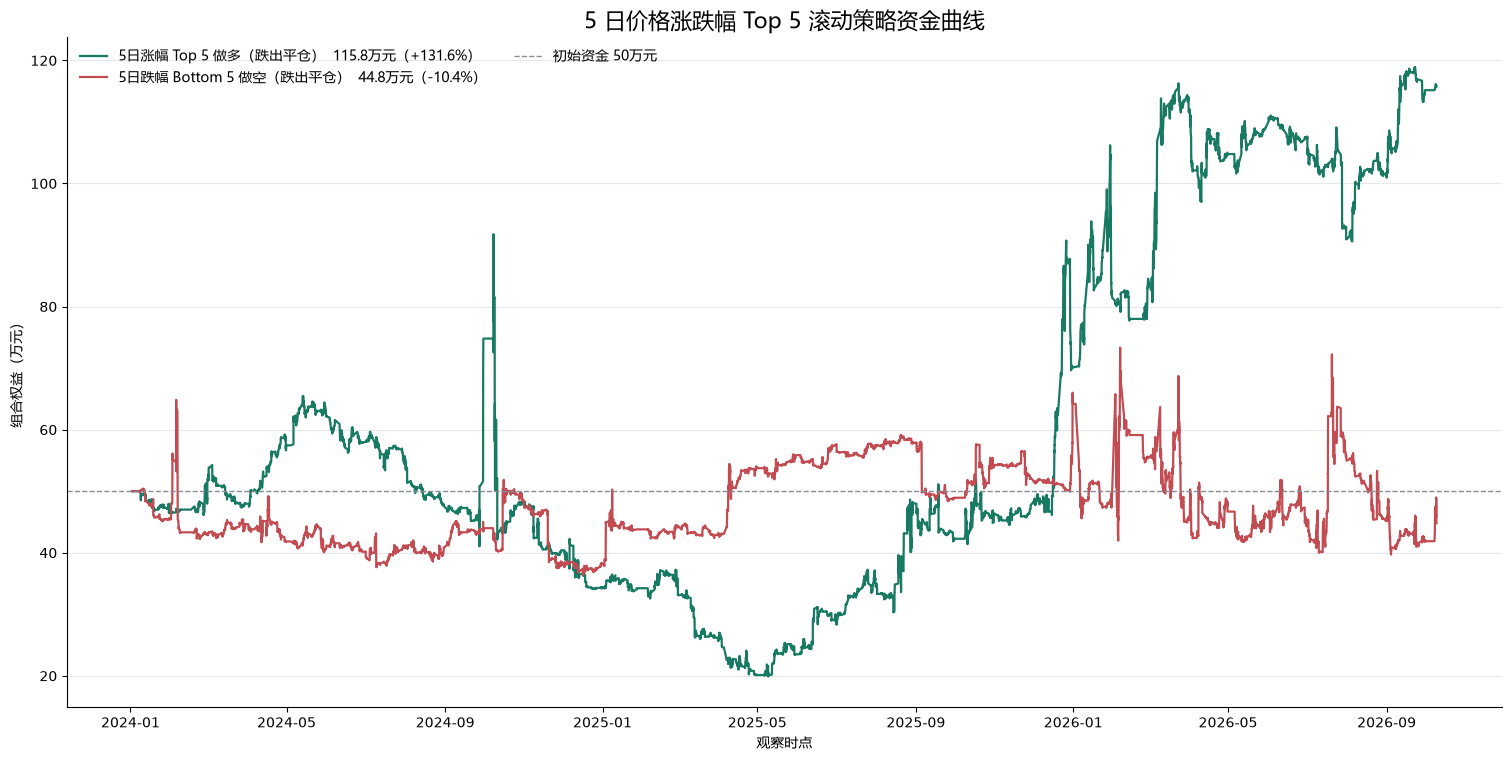

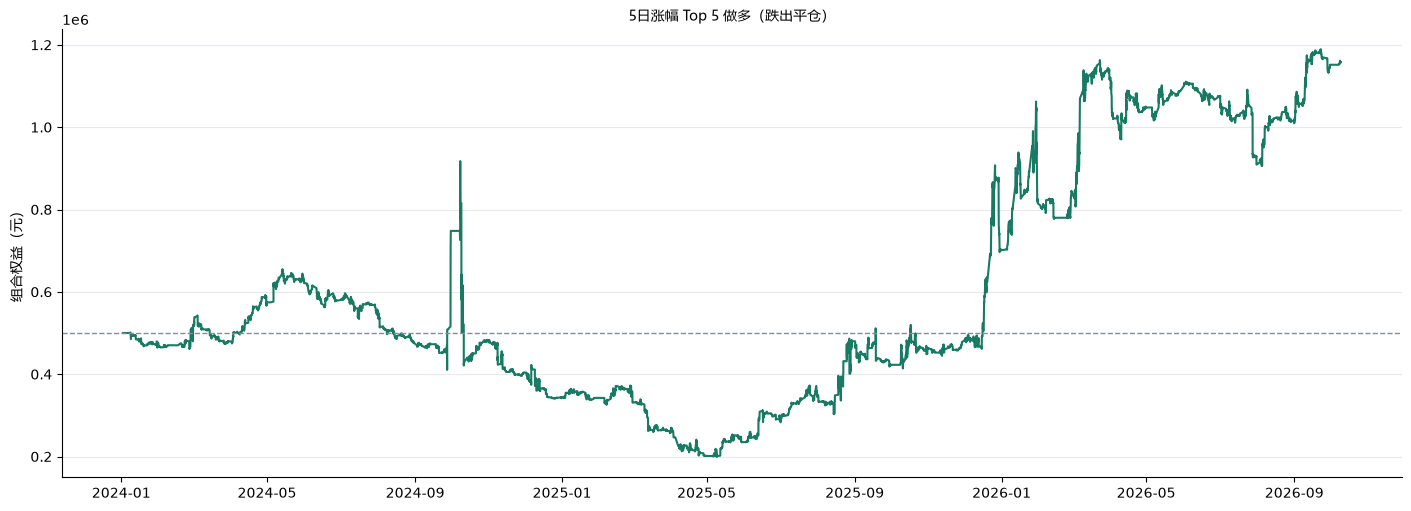

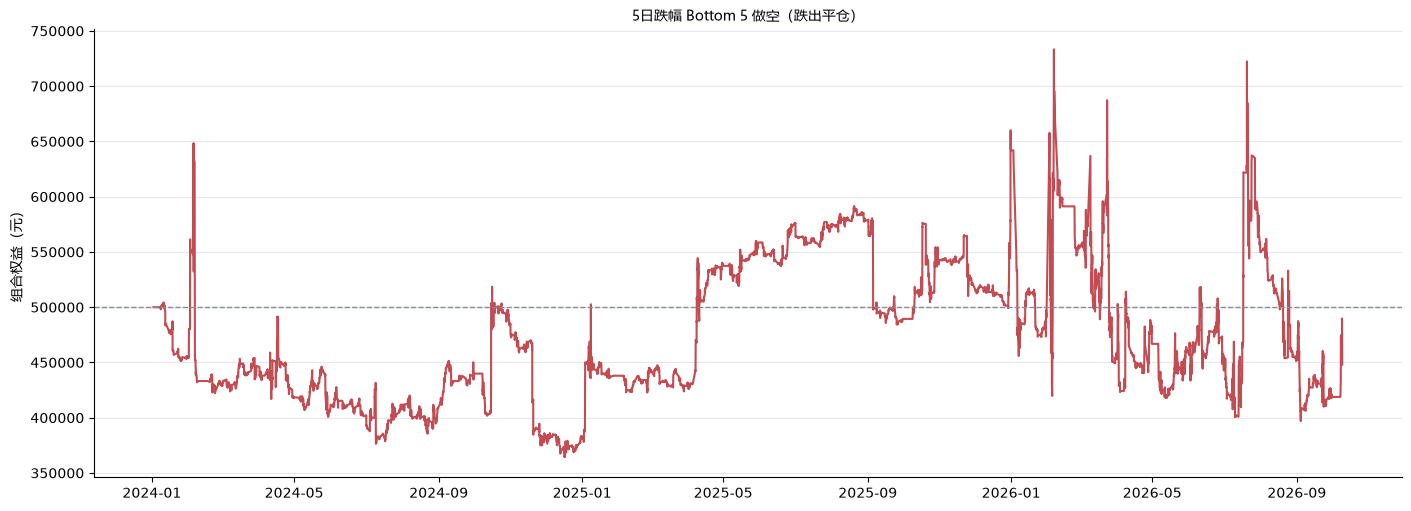

In [193]:
font = FontProperties(fname=r"C:\Windows\Fonts\msyh.ttc")
colors = {"price_top10_long": "#187a63", "price_bottom10_short": "#c34b52"}
fig, ax = plt.subplots(figsize=(15, 7.5), constrained_layout=True)
for key, result in RESULTS.items():
    rows = result["equity_curve"]
    times = [row["timestamp"] for row in rows]
    values = [row["equity"] for row in rows]
    ret = values[-1] / INITIAL_CAPITAL - 1
    ax.plot(times, values, color=colors[key], linewidth=1.6, label=f"{result['summary']['策略']}  {values[-1]/10000:,.1f}万元（{ret:+.1%}）")
ax.axhline(INITIAL_CAPITAL, color="#858c98", linestyle="--", linewidth=1, label="初始资金 50万元")
ax.set_title(f"{LOOKBACK_DAYS} 日价格涨跌幅 Top {TOP_K} 滚动策略资金曲线", fontproperties=font, fontsize=16)
ax.set_xlabel("观察时点", fontproperties=font); ax.set_ylabel("组合权益（万元）", fontproperties=font)
ax.yaxis.set_major_formatter(lambda value, position: f"{value/10000:,.0f}")
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=10)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(axis="y", color="#e5e9ef", linewidth=0.8); ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, prop=font, ncol=2)
fig.savefig(OUTPUT_DIR / "equity_curves_long_short.png", dpi=180, bbox_inches="tight"); plt.show()
for key, result in RESULTS.items():
    fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
    rows = result["equity_curve"]; ax.plot([r["timestamp"] for r in rows], [r["equity"] for r in rows], color=colors[key], linewidth=1.5)
    ax.axhline(INITIAL_CAPITAL, color="#858c98", linestyle="--", linewidth=1); ax.set_title(result["summary"]["策略"], fontproperties=font)
    ax.set_ylabel("组合权益（元）", fontproperties=font); ax.grid(axis="y", color="#e5e9ef", linewidth=0.8); ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=10)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    fig.savefig(OUTPUT_DIR / f"equity_{key}.png", dpi=180, bbox_inches="tight"); plt.show()

## 4. 导出交易记录、权益曲线和持仓快照

In [194]:
def write_rows(path, rows):
    if not rows: return
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8-sig", newline="") as handle:
        writer = DictWriter(handle, fieldnames=list(rows[0]), extrasaction="ignore"); writer.writeheader()
        for row in rows:
            writer.writerow({key: value.isoformat(sep=" ") if isinstance(value, datetime) else value for key, value in row.items()})
for key, result in RESULTS.items():
    write_rows(OUTPUT_DIR / f"trades_{key}.csv", result["trades"])
    write_rows(OUTPUT_DIR / f"equity_curve_{key}.csv", result["equity_curve"])
    write_rows(OUTPUT_DIR / f"positions_{key}.csv", result["positions"])
    write_rows(OUTPUT_DIR / f"rejected_entries_{key}.csv", result["rejected"])
write_rows(OUTPUT_DIR / "summary.csv", [result["summary"] for result in RESULTS.values()])
print("导出目录：", OUTPUT_DIR)

导出目录： d:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\backtest_output\5day_top10_long_short


## 5. 口径核对

- 排名：纯价格 20 日涨跌幅，**不按保证金归一化**，因为老师要求按价格涨幅/跌幅选榜。
- 盈亏：多头`（平仓价−开仓价）×合约乘数`；空头`（开仓价−平仓价）×合约乘数`，不额外乘杠杆。
- 归一化：交易记录的`保证金收益率 = 净盈亏 ÷ 入场保证金`；汇总的`累计收益/平均保证金 = 净盈亏 ÷ 时间加权平均保证金`。保证金率由 WT8 的权益−可用资金估算。
- 手续费、滑点为 0；主连换月价差不直接记入价格盈亏，结果是研究性近似模拟。

## 6. 自动核对回测约束
下面的断言确保每个组合最多十个品种、每笔交易严格一手，并确认导出的策略结果与运行结果一致。

In [195]:
for key, result in RESULTS.items():
    max_positions = max(point["positions"] for point in result["equity_curve"])
    assert max_positions <= TOP_K, (key, max_positions)
    assert all(trade.get("手数") == 1 for trade in result["trades"])
    assert all((row.get("入场保证金") or 0) >= 0 for row in result["trades"])
    print(key, "通过：最大持仓", max_positions, "，交易笔数", len(result["trades"]))
print("核对完成：价格排名不做保证金归一化；收益按合约乘数计算，保证金收益率单独记录。")

price_top10_long 通过：最大持仓 5 ，交易笔数 2755
price_bottom10_short 通过：最大持仓 5 ，交易笔数 2745
核对完成：价格排名不做保证金归一化；收益按合约乘数计算，保证金收益率单独记录。
